## Variables de relief du projet African Crop Yield Intelligence

Ce notebook contrôle le modèle numérique de terrain acquis pour le projet et les variables de relief construites pour chaque lieu de `regional` et de `survey`. Il fait suite à `07_soil_variables.ipynb` et clôt l'acquisition du premier lot de variables explicatives.

**Décisions de départ**

- Le relief provient de Copernicus DEM, source retenue à la section 5.1 de `docs/explanatory_variables.md`, dans sa version GLO-90 à 3 secondes d'arc, soit 90 m environ. La version à 30 m, neuf fois plus volumineuse, n'apporterait rien à l'échelle des lieux du projet, dont le plus petit est un voisinage de 5 km.
- Deux variables sont construites, l'altitude moyenne et la pente moyenne, conformément à la proposition initiale.
- La pente est calculée à 90 m par la méthode de Horn, avec un pas est-ouest qui diminue avec le cosinus de la latitude. La mer, les lacs et les rivières, repérés par le masque des eaux qui accompagne chaque tuile, sont écartés.
- L'altitude et la pente sont moyennées sur la grille à 1 km de SoilGrids, qui conserve les surfaces, chaque pixel de 90 m étant pondéré par sa surface. Les lieux sont ceux des variables climatiques et des sols.

**Préalable**

Les tuiles sont traitées par `python -m src.features.relief extraire`, puis la mosaïque et les variables sont construites par `python -m src.features.relief construire`, qui écrit `relief_regional.csv.gz` et `relief_survey.csv.gz` dans `data/processed`. Le notebook s'exécute en moins d'une minute.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from pyproj import Transformer

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.data.load import DOSSIER_TRAITE
from src.features.climat import DOSSIER_MAGASIN
from src.features.relief import DOSSIER_COPERNICUS, DOSSIER_RELIEF
from src.features.sols import CRS_SOILGRIDS

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

### 1. Tests unitaires

Les tests propres au relief vérifient le nom des tuiles, leur sélection, la pente d'un plan incliné à l'équateur et à 60 degrés de latitude, l'agrégation pondérée sur la grille à 1 km et le masquage des eaux.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 86 tests in 1.476s', '', 'OK']


### 2. Intégrité des sources

Le serveur de Copernicus DEM publie l'empreinte MD5 de chaque fichier dans son ETag. Chaque tuile et son masque des eaux ont été téléchargés, comparés à cette empreinte, traités puis supprimés. Seul un résumé par tuile est conservé dans `data/interim/relief/tuiles`, avec, pour chaque pixel à 1 km touché, la somme des poids et les sommes pondérées de l'altitude et de la pente.

In [3]:
sources = pd.read_csv(DOSSIER_COPERNICUS / "sources.csv")
masques = sources["url"].str.contains("_WBM.tif")
resumes = sorted(p.name for p in (DOSSIER_RELIEF / "tuiles").glob("*_DEM.npz"))
print("Tuiles vérifiées :", int((~masques).sum()), "| masques vérifiés :", int(masques.sum()),
      "| résumés conservés :", len(resumes), "| doublons :", int(sources.duplicated("url").sum()))
print("Volume vérifié puis supprimé :", round(sources["octets"].sum() / 1e9, 2), "Go",
      "| volume des résumés :", round(sum((DOSSIER_RELIEF / "tuiles" / n).stat().st_size for n in resumes) / 1e6), "Mo")
print("Tuiles sans résumé :", sorted(set(sources.loc[~masques, "tuile"]) - {n[:-4] for n in resumes}))
print("Dates de dernière modification :", sorted(pd.to_datetime(sources["derniere_modification"], format="%a, %d %b %Y %H:%M:%S GMT").dt.date.unique()))

Tuiles vérifiées : 2408 | masques vérifiés : 2408 | résumés conservés : 2408 | doublons : 0
Volume vérifié puis supprimé : 10.86 Go | volume des résumés : 486 Mo
Tuiles sans résumé : []
Dates de dernière modification : [datetime.date(2022, 5, 9)]


**Constat**

- Les 2 408 tuiles publiées qui recoupent un lieu du projet ont été traitées, sans échec. La seule tuile recoupant un lieu qui ne soit pas publiée se trouve au large de Quelimane, au Mozambique, et ne contient aucune terre émergée.
- Les 4 816 fichiers, tuiles et masques, ont tous l'empreinte publiée. Ils totalisent 10,86 Go et datent tous du 9 mai 2022. Les résumés conservés occupent 486 Mo.

**Analyse**

Comme pour les sols, la vérification porte sur des fichiers complets. Les résumés permettent de reprendre une extraction interrompue sans retraiter les tuiles déjà résumées, et de reconstruire la mosaïque sans nouveau téléchargement.

### 3. Plausibilité de la mosaïque

La mosaïque à 1 km est résumée, puis confrontée à l'altitude connue de quelques villes et d'un sommet. Les cartes montrent l'altitude et la pente moyennes, les zones blanches correspondant à la mer et aux tuiles qui ne recoupent aucun lieu.

Pixels à 1 km avec terre émergée : 26376069 soit 0.444 de la fenêtre


,altitude,pente
minimum,-153.66,0.00
q01,10.11,0.06
mediane,495.72,1.21
q99,2078.75,19.00
maximum,5779.87,47.42


,lieu,altitude de reference,altitude moyenne du pixel,pente moyenne du pixel
0,Niamey,210,193.699997,2.1
1,Bamako,350,346.500000,4.0
2,Addis-Abeba,2350,2379.199951,3.7
3,Nairobi,1700,1668.500000,1.0
4,Lilongwe,1050,1051.800049,2.1
5,Antananarivo,1280,1267.000000,4.4
6,Johannesburg,1750,1731.599976,1.9
7,Sommet du Kilimandjaro,5895,5779.899902,9.1


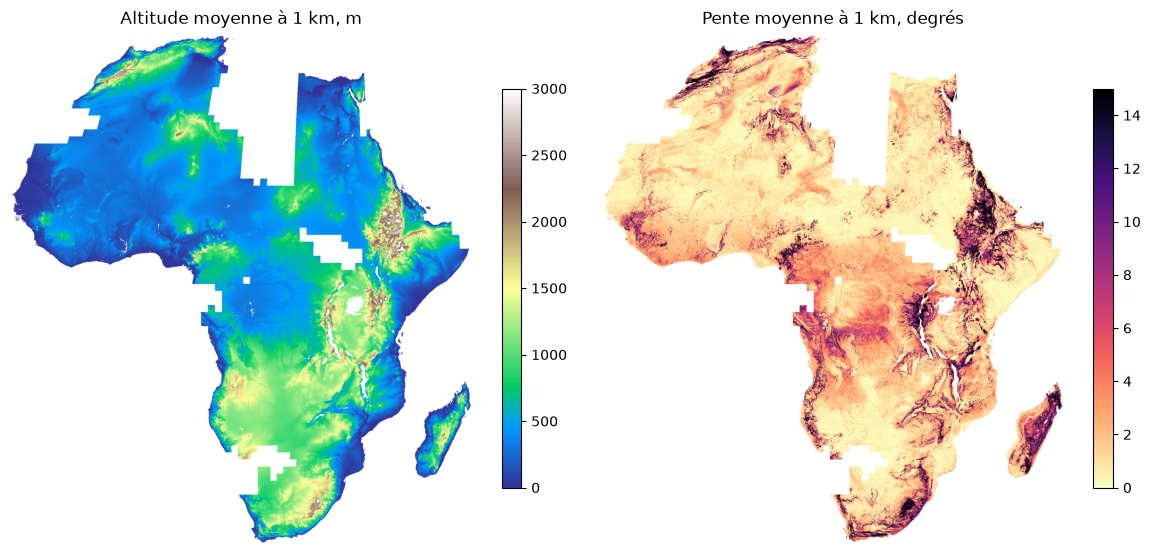

In [4]:
couches = {}
for nom in ["altitude", "pente"]:
    with rasterio.open(DOSSIER_RELIEF / f"{nom}_1km.tif") as raster:
        couches[nom] = raster.read(1)
        transformation = raster.transform
valides = ~np.isnan(couches["altitude"])
print("Pixels à 1 km avec terre émergée :", int(valides.sum()), "soit", round(valides.mean(), 3), "de la fenêtre")
display(pd.DataFrame({nom: np.nanpercentile(c, [0, 1, 50, 99, 100]) for nom, c in couches.items()},
                     index=["minimum", "q01", "mediane", "q99", "maximum"]).round(2))

points = {
    "Niamey": (2.11, 13.51, 210), "Bamako": (-8.0, 12.65, 350), "Addis-Abeba": (38.75, 9.02, 2350),
    "Nairobi": (36.82, -1.29, 1700), "Lilongwe": (33.78, -13.97, 1050), "Antananarivo": (47.52, -18.91, 1280),
    "Johannesburg": (28.05, -26.2, 1750), "Sommet du Kilimandjaro": (37.355, -3.066, 5895),
}
projection = Transformer.from_crs("EPSG:4326", CRS_SOILGRIDS, always_xy=True)
lignes = []
for nom, (lon, lat, reference) in points.items():
    x, y = projection.transform(lon, lat)
    colonne, ligne = (~transformation) @ (x, y)
    lignes.append({"lieu": nom, "altitude de reference": reference,
                   "altitude moyenne du pixel": couches["altitude"][int(ligne), int(colonne)],
                   "pente moyenne du pixel": couches["pente"][int(ligne), int(colonne)]})
display(pd.DataFrame(lignes).round(1))

figure, axes = plt.subplots(1, 2, figsize=(12, 6))
for axe, (nom, carte, borne) in zip(axes, [("altitude", "terrain", 3000), ("pente", "magma_r", 15)]):
    image = axe.imshow(couches[nom][::4, ::4], cmap=carte, vmin=0, vmax=borne)
    axe.set_title(f"{nom.capitalize()} moyenne à 1 km, {'m' if nom == 'altitude' else 'degrés'}")
    axe.set_axis_off()
    figure.colorbar(image, ax=axe, shrink=0.7)
plt.tight_layout()
plt.show()
del couches

**Constat**

- 44,4 % des pixels de la fenêtre ont une terre émergée. L'altitude va de -154 m, sur les rives du lac Assal à Djibouti, à 5 780 m, et la pente moyenne d'un pixel de 0 à 47 degrés.
- L'altitude des sept villes de contrôle s'écarte de 2 à 32 m de leur altitude de référence, sauf au sommet du Kilimandjaro, où le pixel de 1 km moyenne des pentes qui descendent sous le sommet.
- Les cartes retrouvent les hauts plateaux d'Éthiopie et d'Afrique australe, le rift est-africain et l'escarpement de Madagascar.
- Dans la cuvette congolaise, où l'altitude ne varie que de 307 à 384 m sur quatre degrés de longitude, la pente médiane atteint 1,4 degré, contre 0,5 degré dans la plaine sahélienne du Niger et 0,2 degré dans la plaine du Soudan du Sud. Ce contrôle exploratoire n'est pas reproduit dans le notebook.

**Analyse**

- L'altitude est exacte à quelques dizaines de mètres près, ce qui suffit largement à l'usage agronomique.
- Copernicus DEM est un modèle numérique de surface, qui mesure le sommet de la canopée et des bâtiments plutôt que le sol. Sous la forêt dense, les variations de hauteur des arbres créent une pente apparente d'environ un degré, qui s'ajoute à la pente réelle.

**Conséquences pour la suite**

La pente des zones forestières est surestimée d'un degré environ. Ce biais concerne surtout le bassin du Congo et la côte guinéenne, et reste faible devant les pentes des zones de montagne, qui dépassent 8 degrés en médiane au Lesotho, au Rwanda, au Burundi et à Madagascar.

### 4. Comparaison avec l'altitude de MERRA-2

L'altitude de chaque zone de `regional` est comparée à l'altitude des mailles de MERRA-2 diffusée par NASA POWER, moyennée avec les poids des variables climatiques. Les deux sources sont indépendantes, MERRA-2 décrivant un relief lissé à la résolution de sa grille de 0,5 sur 0,625 degré.

In [5]:
relief_regional = pd.read_csv(DOSSIER_TRAITE / "relief_regional.csv.gz")
mailles = pd.read_csv(DOSSIER_MAGASIN / "power_mailles.csv").set_index("maille")
poids = pd.read_csv(DOSSIER_MAGASIN / "poids_regional.csv")
poids = poids.assign(altitude=poids["maille"].map(mailles["altitude"]))
merra = (poids["altitude"] * poids["poids"]).groupby(poids["lieu"]).sum() / poids.groupby("lieu")["poids"].sum()
comparaison = relief_regional.set_index("GDAM_ID").join(merra.rename("altitude_merra2")).dropna(
    subset=["altitude_moyenne", "altitude_merra2"])
ecart = comparaison["altitude_moyenne"] - comparaison["altitude_merra2"]
print("Zones comparées :", len(comparaison), "| corrélation :", round(comparaison["altitude_moyenne"].corr(comparaison["altitude_merra2"]), 3),
      "| écart médian :", round(ecart.median(), 1), "m | écart absolu médian :", round(ecart.abs().median(), 1), "m")
display(pd.concat([comparaison, ecart.rename("ecart")], axis=1).reindex(ecart.abs().sort_values(ascending=False).index)
        [["altitude_moyenne", "altitude_merra2", "ecart", "pente_moyenne"]].head(8).round(1))

Zones comparées : 1682 | corrélation : 0.992 | écart médian : -1.0 m | écart absolu médian : 13.9 m


,altitude_moyenne,altitude_merra2,ecart,pente_moyenne
GDAM_ID,,,,
L1ERI0877,2213.0,1493.9,719.1,7.7
L2CMR09737,1578.3,997.3,581.0,7.8
L1MWI2086,1481.8,979.2,502.6,8.9
L1UGA3317,2004.2,1540.3,463.9,9.4
L2ETH14643,2203.8,1780.4,423.4,10.0
L1LSO1727,2732.3,2316.0,416.3,15.7
L1KEN1528,2535.9,2125.9,410.1,5.8
L2TGO38636,723.7,317.0,406.7,9.0


**Constat**

- Sur les 1 682 zones, la corrélation entre les deux altitudes atteint 0,992. L'écart médian vaut -1 m et l'écart absolu médian 14 m.
- Les plus grands écarts concernent des zones de hauts plateaux bordés de vallées profondes, comme une région d'Érythrée, où Copernicus DEM donne 2 213 m et MERRA-2 1 494 m, ou des régions du Cameroun, du Malawi, de l'Ouganda, de l'Éthiopie, du Lesotho et du Kenya. L'altitude de Copernicus DEM y est toujours la plus élevée.

**Analyse**

L'accord général confirme l'assemblage de la mosaïque et le placement des pixels. Les écarts s'expliquent par le lissage de MERRA-2, qui abaisse les plateaux étroits en les moyennant avec les basses terres voisines. L'altitude de Copernicus DEM est la plus fidèle à l'échelle des zones.

### 5. Variables par lieu

La valeur d'un lieu est la moyenne de ses pixels à 1 km valides, selon les règles appliquées aux sols. La part de pixels valides est la part de pixels contenant une terre émergée.

In [6]:
relief_survey = pd.read_csv(DOSSIER_TRAITE / "relief_survey.csv.gz")
lieux_survey = relief_survey.drop_duplicates("lieu").dropna(subset=["lieu"])
print("regional :", relief_regional.shape, "| survey :", relief_survey.shape)
print("Zones de regional sans valeur :", relief_regional.loc[relief_regional["altitude_moyenne"].isna(), "GDAM_ID"].tolist())
print("Lieux de survey sans valeur :", lieux_survey.loc[lieux_survey["altitude_moyenne"].isna(), "lieu"].tolist())
print("Lignes avec relief, regional :", round(pd.read_csv(DOSSIER_TRAITE / "regional_modelisation.csv.gz", usecols=["GDAM_ID"])["GDAM_ID"]
      .map(relief_regional.set_index("GDAM_ID")["altitude_moyenne"]).notna().mean(), 4),
      "| survey :", round(relief_survey["altitude_moyenne"].notna().mean(), 4))
display(pd.DataFrame({
    "regional": relief_regional[["altitude_moyenne", "pente_moyenne", "part_relief_valide"]].describe().stack(),
    "grappes": lieux_survey.loc[lieux_survey["nature_lieu"] == "grappe", ["altitude_moyenne", "pente_moyenne", "part_relief_valide"]].describe().stack(),
}).unstack(0).round(2))
pays = pd.read_csv(DOSSIER_TRAITE / "regional_modelisation.csv.gz", usecols=["GDAM_ID", "country"]).drop_duplicates("GDAM_ID")
par_pays = relief_regional.merge(pays, on="GDAM_ID").groupby("country")[["altitude_moyenne", "pente_moyenne"]].median()
display(par_pays.sort_values("pente_moyenne", ascending=False).round(1).T)
print("Corrélation de rang entre altitude et pente des zones :",
      round(relief_regional["altitude_moyenne"].rank().corr(relief_regional["pente_moyenne"].rank()), 2))

regional : (1682, 5) | survey : (151138, 7)
Zones de regional sans valeur : []
Lieux de survey sans valeur : []


Lignes avec relief, regional : 1.0 | survey : 0.9928


regional                                                         grappes                                                        
                      count    mean     std   min     25%     50%      75%      max   count    mean     std   min     25%     50%      75%      max
altitude_moyenne     1682.0  605.84  558.93  0.35  174.21  387.46  1025.05  2732.31  8045.0  762.34  582.80  1.79  284.18  609.54  1180.45  3357.79
pente_moyenne        1682.0    3.40    3.27  0.10    1.02    2.25     4.79    18.36  8045.0    3.37    3.57  0.07    0.95    1.98     4.61    26.34
part_relief_valide   1682.0    0.99    0.05  0.05    1.00    1.00     1.00     1.00  8045.0    0.99    0.06  0.15    1.00    1.00     1.00     1.00

country,Lesotho,Rwanda,Burundi,Madagascar,Ethiopia,Eritrea,Swaziland,Morocco,Guinea,Algeria,Cameroon,Republic of the Congo,Malawi,Sierra Leone,Liberia,Kenya,Angola,South Africa,Uganda,Democratic Republic of the Congo,...,Central African Republic,Mozambique,Nigeria,Togo,Zambia,Guinea-Bissau,Benin,Egypt,Mauritania,Mali,Niger,Gambia,Burkina Faso,Sudan,Chad,Senegal,Botswana,Somalia,Namibia,South Sudan
altitude_moyenne,2109.5,1735.3,1563.4,499.0,1615.3,827.9,767.6,502.5,472.6,589.5,654.3,446.8,832.8,119.4,121.2,1363.1,978.8,1021.0,1141.6,580.7,...,543.6,283.3,249.5,270.5,1149.0,16.6,130.5,110.4,131.7,299.5,374.6,18.1,299.5,504.5,383.1,30.8,995.8,170.9,1131.0,407.2
pente_moyenne,13.4,10.8,8.7,8.2,7.7,7.7,7.7,5.8,5.4,5.3,5.2,4.7,4.6,4.1,3.8,3.7,3.4,3.4,3.1,2.9,...,2.3,2.2,1.9,1.9,1.6,1.3,1.2,1.2,1.0,0.8,0.8,0.7,0.7,0.7,0.6,0.5,0.5,0.5,0.4,0.2


Corrélation de rang entre altitude et pente des zones : 0.55


**Constat**

- Toutes les zones de `regional` et tous les lieux de `survey` reçoivent une altitude et une pente. 100 % des lignes de `regional` et 99,28 % des lignes de `survey` en disposent, les lignes restantes étant les 1 085 lignes sans localisation.
- L'altitude médiane des zones vaut 387 m et celle des voisinages de grappes 610 m. La pente médiane vaut 2,3 degrés pour les zones et 2,0 degrés pour les grappes, avec un maximum de 18,4 et de 26,3 degrés.
- Les pays les plus pentus sont le Lesotho, à 13,4 degrés en médiane des zones, le Rwanda, à 10,8 degrés, et le Burundi, à 8,7 degrés. Les plus plats sont le Soudan du Sud, la Namibie, le Botswana, la Somalie et le Sénégal, à 0,5 degré ou moins.
- La corrélation de rang entre l'altitude et la pente des zones vaut 0,55.

**Analyse**

- Contrairement aux sols, le relief est défini dans les villes, ce qui donne une couverture complète.
- Les enquêtes de `survey` portent davantage sur les hautes terres que `regional`, sous l'effet des pays enquêtés, notamment l'Éthiopie.
- La corrélation modérée entre altitude et pente montre que les deux variables portent des informations distinctes, les hauts plateaux pouvant être plats et certaines basses terres accidentées.

**Décision**

Les deux variables sont conservées avec `pixels_relief` et `part_relief_valide`. L'altitude de Copernicus DEM remplace celle de MERRA-2 comme variable explicative. L'altitude de MERRA-2 reste utilisée pour la pression atmosphérique du calcul de l'évapotranspiration, qui doit rester cohérente avec les variables météorologiques de la même maille.

### 6. Synthèse

**Résultats**

| Élément | Résultat |
|---|---|
| Tuiles traitées | 2 408 tuiles et leurs masques des eaux, vérifiés par l'empreinte MD5 publiée |
| Volume conservé | 486 Mo de résumés, pour 10,86 Go de sources vérifiées puis supprimées |
| Exactitude de l'altitude | De 2 à 32 m d'écart sur sept villes de contrôle, corrélation de 0,992 avec MERRA-2 |
| `relief_regional.csv.gz` | 1 682 zones, clé `GDAM_ID`, aucune valeur manquante |
| `relief_survey.csv.gz` | 151 138 lignes, clé `id_ligne`, 99,28 % avec relief |

**Limites**

- Copernicus DEM décrit la surface de la canopée et des bâtiments. La pente des zones de forêt dense est surestimée d'un degré environ.
- La pente des pixels situés au bord d'une tuile est calculée en prolongeant la tuile, faute de lire sa voisine. Cette approximation touche une ligne ou une colonne de pixels de 90 m sur 1 200 de chaque côté, soit 0,3 % des pixels.
- La pente moyenne ne distingue pas une zone uniformément inclinée d'une zone qui mêle plaines et reliefs escarpés. Une variable de dispersion pourra être ajoutée si la modélisation en montre l'utilité.